In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/original_Macular Scar1081_79.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/original_Macular Scar1063_732.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/augmented_Macular Scar1780_1400.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/original_Macular Scar1922_651.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/augmented_Macular Scar1570_2378.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/augmented_Macular Scar1379_1839.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/augmented_Macular Scar1579_1716.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Macular Scar/augmented_Macular Scar1313_1511.jpg
/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6/val/Mac

**Project Summary:**
*  Data Augmentation
* Split dataset
* Build Custom CNN
* Apply Pruning on Custom CNN
* Apply Knowledge Distillation
* XAI(GradCAM,LIME)

# Import Required Libraries 

In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import torch.nn.utils.prune as prune
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import seaborn as sns
import cv2
import torch.nn.functional as F
from torchsummary import summary
import time
import gzip
from itertools import cycle
from torch.utils.data import DataLoader

In [4]:
# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


# Data Augmentation

In [ ]:
TARGET_SHAPE = (224, 224)


augmentation_transforms = [
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.5),
    transforms.ColorJitter(saturation=0.2, hue=0.2),
]


def random_augment(image):
    num_augmentations = np.random.randint(1, 4)  
    selected_transforms = np.random.choice(augmentation_transforms, num_augmentations, replace=False)
    
    transform = transforms.Compose([
        *selected_transforms,
        transforms.Resize(TARGET_SHAPE),
    ])
    
    return transform(image)


def save_image(image, save_path, original_name, count, prefix="original"):
    base_name = os.path.splitext(original_name)[0]  # Remove file extension
    save_filename = f"{prefix}_{base_name}_{count}.jpg"
    image.save(os.path.join(save_path, save_filename))


def load_data_and_save_augmented(folder_path, augmented_folder_path, target_images_per_class=2500):
    classes = ["Macular Scar", "Myopia", "cataract", "diabetic_retinopathy", "glaucoma", "normal"]
    
    for category in classes:
        category_folder = os.path.join(folder_path, category)
        augmented_category_folder = os.path.join(augmented_folder_path, category)
        os.makedirs(augmented_category_folder, exist_ok=True)
        
        image_files = os.listdir(category_folder)
        num_original_images = len(image_files)
        
        count = 0  
        augmented_count = num_original_images  
        
        for file_name in image_files:
            image_path = os.path.join(category_folder, file_name)
            image = Image.open(image_path).convert("RGB")  
            
            
            save_image(image, augmented_category_folder, file_name, count, prefix="original")
            count += 1
            
        while augmented_count < target_images_per_class:
            file_name = np.random.choice(image_files) 
            image_path = os.path.join(category_folder, file_name)
            image = Image.open(image_path).convert("RGB")
            
            augmented_image = random_augment(image) 
            
            
            save_image(augmented_image, augmented_category_folder, file_name, count, prefix="augmented")
            count += 1
            augmented_count += 1
    
folder_path = "/kaggle/input/dataset-kaggle-6/Kaggle_6/dataset"  
augmented_folder_path = "/kaggle/working/augmented_dataset_kaggle_6"  

load_data_and_save_augmented(folder_path, augmented_folder_path)

# Dataset Split

In [ ]:
!pip install split-folders
import splitfolders

input_file = "/kaggle/working/augmented_dataset_kaggle_6"  
output_file = "/kaggle/working/split_dataset_augmented_kaggle_6"     

splitfolders.ratio(
    input_file, 
    output=output_file, 
    seed=42, 
    ratio=(0.7, 0.1, 0.20), 
    group_prefix=None
)

# Set Up Device and Hyperparameters

In [27]:
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 6
LEARNING_RATE = 0.001
NUM_EPOCHS = 50
PATIENCE = 5
FINE_TUNE_LR = 0.0001
NUM_FINE_TUNE_EPOCHS = 5

DISTILLATION_TEMPERATURE = 2.0
ALPHA_KD = 0.9  


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Define Dataset Paths

Dataset Summary:
Training samples: 10500
Validation samples: 1500
Test samples: 3000
Classes: ['Macular Scar', 'Myopia', 'cataract', 'diabetic_retinopathy', 'glaucoma', 'normal']


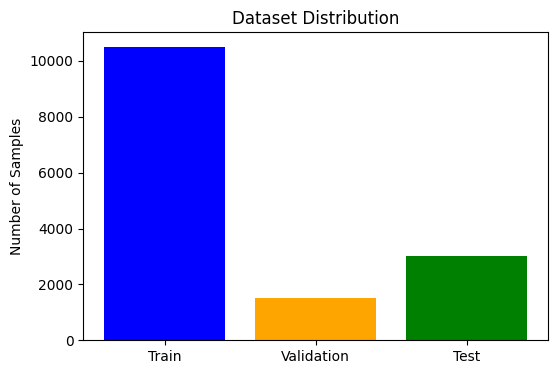

In [28]:
dataset_dir = "/kaggle/input/eye-datase-split/split_dataset_augmented_kaggle_6"
train_dir = os.path.join(dataset_dir, "train")
validation_dir = os.path.join(dataset_dir, "val")
test_dir = os.path.join(dataset_dir, "test")


train_dataset = datasets.ImageFolder(root=train_dir, transform=transform)
val_dataset = datasets.ImageFolder(root=validation_dir, transform=transform)
test_dataset = datasets.ImageFolder(root=test_dir, transform=transform)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)


print("Dataset Summary:")
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Classes: {train_dataset.classes}")
plt.figure(figsize=(6, 4))
plt.bar(['Train', 'Validation', 'Test'], [len(train_dataset), len(val_dataset), len(test_dataset)], color=['blue', 'orange', 'green'])
plt.title('Dataset Distribution')
plt.ylabel('Number of Samples')
plt.show()

# Custom CNN Model 

In [38]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(CustomCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 96, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(96)
        self.conv4 = nn.Conv2d(96, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(256 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))
        x = self.pool(torch.relu(self.bn4(self.conv4(x))))
        x = self.pool(torch.relu(self.bn5(self.conv5(x))))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

# Utility Functions

In [39]:
# Evaluation Function
def evaluate_model(model, loader, criterion, device, model_name="model", class_names=None):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    all_predictions, all_labels, all_probs = [], [], []
    inference_times = []
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            start_time = time.time()
            outputs = model(images)
            end_time = time.time()
            inference_times.append(end_time - start_time)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
    
    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)
    
    accuracy = 100 * accuracy_score(all_labels, all_predictions)
    precision = 100 * precision_score(all_labels, all_predictions, average='weighted')
    recall = 100 * recall_score(all_labels, all_predictions, average='weighted')
    f1 = 100 * f1_score(all_labels, all_predictions, average='weighted')
    avg_loss = total_loss / len(loader)
    avg_inference_time = np.mean(inference_times) * 1000
    
    print(f"\nEvaluation Metrics for {model_name}:")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Precision: {precision:.2f}%")
    print(f"Recall: {recall:.2f}%")
    print(f"F1 Score: {f1:.2f}%")
    print(f"Average Inference Time per Batch: {avg_inference_time:.2f} ms")
    
    return accuracy, precision, recall, f1, avg_loss, avg_inference_time, all_predictions, all_labels, all_probs

# Plot Training Curves
def plot_training_curves(train_losses, val_losses, train_accuracies, val_accuracies, model_name="Model"):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss')
    plt.plot(val_losses, label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title(f'{model_name} Loss Curves')
    
    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label='Train Accuracy')
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.title(f'{model_name} Accuracy Curves')
    plt.show()

# Plot Confusion Matrix
def plot_confusion_matrix(true_labels, pred_labels, class_names, model_name="Model"):
    cm = confusion_matrix(true_labels, pred_labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix for {model_name}')
    plt.show()

# Plot ROC Curve
def plot_roc_curve(true_labels, pred_probs, class_names, model_name="Model"):
    n_classes = len(class_names)
    true_labels_bin = label_binarize(true_labels, classes=range(n_classes))
    roc_auc = {}
    fpr = {}
    tpr = {}
    
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(true_labels_bin[:, i], pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    fpr["micro"], tpr["micro"], _ = roc_curve(true_labels_bin.ravel(), pred_probs.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
    
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
    
    plt.figure(figsize=(8, 6))
    plt.plot(fpr["micro"], tpr["micro"],
             label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.2f})',
             color='deeppink', linestyle=':', linewidth=4)
    plt.plot(fpr["macro"], tpr["macro"],
             label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.2f})',
             color='navy', linestyle=':', linewidth=4)
    
    colors = plt.cm.get_cmap('tab10')(np.linspace(0, 1, n_classes))
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'ROC curve of {class_names[i]} (AUC = {roc_auc[i]:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()
    
    return roc_auc

# Calculate Model Size
def calculate_model_size(model, model_name="model", compress=True):
    if compress:
        with gzip.open(f"{model_name}.pth.gz", 'wb') as f:
            torch.save(model.state_dict(), f)
        size_mb = os.path.getsize(f"{model_name}.pth.gz") / (1024 * 1024)
        os.remove(f"{model_name}.pth.gz")
    else:
        torch.save(model.state_dict(), f"{model_name}.pth")
        size_mb = os.path.getsize(f"{model_name}.pth") / (1024 * 1024)
        os.remove(f"{model_name}.pth")
    return size_mb

# Training Function

In [40]:
def train_custom_model(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs, device, model_name="custom_cnn"):
    model.train()
    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []
    
    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
        
        avg_train_loss = total_loss / len(train_loader)
        train_accuracy = 100 * correct / total
        train_losses.append(avg_train_loss)
        train_accuracies.append(train_accuracy)
        
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)
        
        avg_val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * val_correct / val_total
        val_losses.append(avg_val_loss)
        val_accuracies.append(val_accuracy)
        
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), f"{model_name}.pth")
            print(f"Best {model_name} model saved!")
        else:
            epochs_no_improve += 1
        
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
        
        scheduler.step(avg_val_loss)
    
    return model, train_losses, val_losses, train_accuracies, val_accuracies

# Train and Evaluate CustomCNN

CustomCNN Model Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 224, 224]             896
       BatchNorm2d-2         [-1, 32, 224, 224]              64
         MaxPool2d-3         [-1, 32, 112, 112]               0
            Conv2d-4         [-1, 64, 112, 112]          18,496
       BatchNorm2d-5         [-1, 64, 112, 112]             128
         MaxPool2d-6           [-1, 64, 56, 56]               0
            Conv2d-7           [-1, 96, 56, 56]          55,392
       BatchNorm2d-8           [-1, 96, 56, 56]             192
         MaxPool2d-9           [-1, 96, 28, 28]               0
           Conv2d-10          [-1, 128, 28, 28]         110,720
      BatchNorm2d-11          [-1, 128, 28, 28]             256
        MaxPool2d-12          [-1, 128, 14, 14]               0
           Conv2d-13          [-1, 256, 14, 14]         295,168
      BatchNor

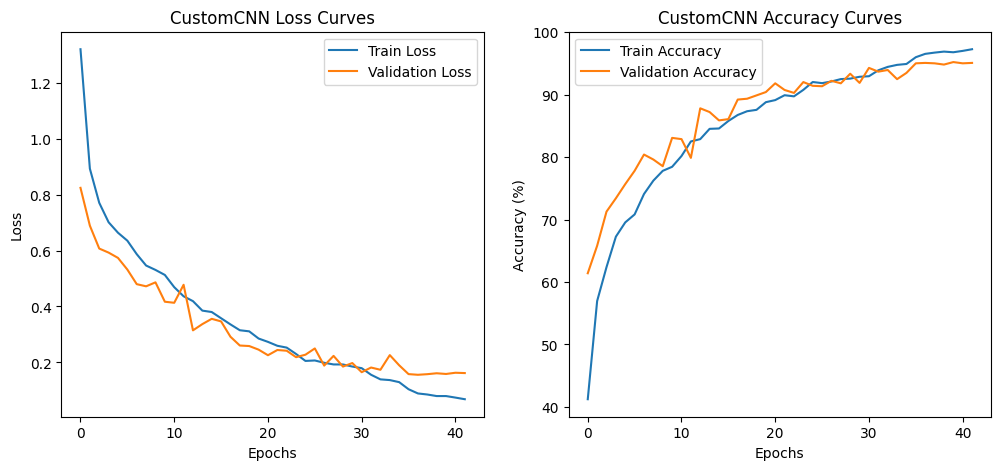

/tmp/ipykernel_31/1565973430.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  custom_model.load_state_dict(torch.load("custom_cnn.pth"))



Evaluation Metrics for CustomCNN Model:
Accuracy: 95.07%
Precision: 95.10%
Recall: 95.07%
F1 Score: 95.06%
Average Inference Time per Batch: 1.38 ms
CustomCNN (Teacher) Model Size: 7.42 MB


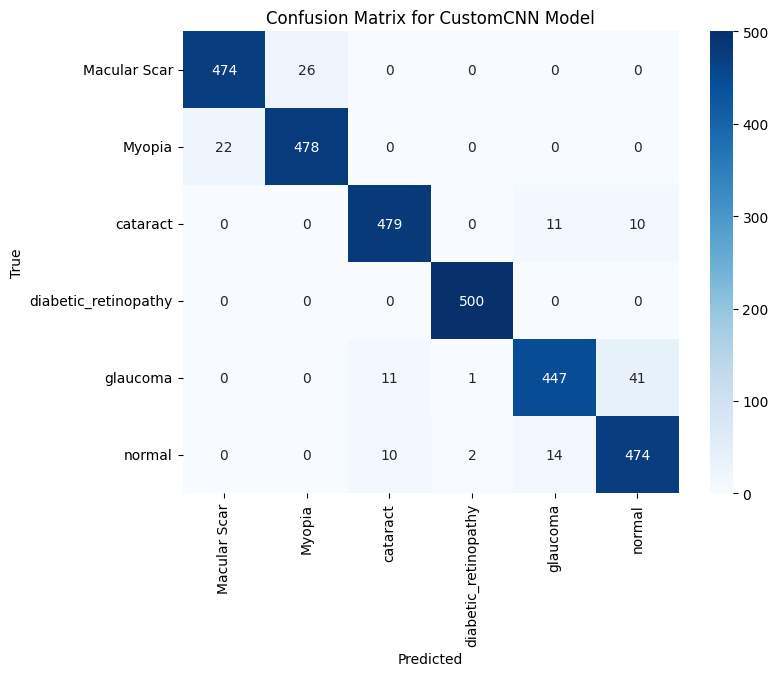

/tmp/ipykernel_31/3166562010.py:107: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab10')(np.linspace(0, 1, n_classes))


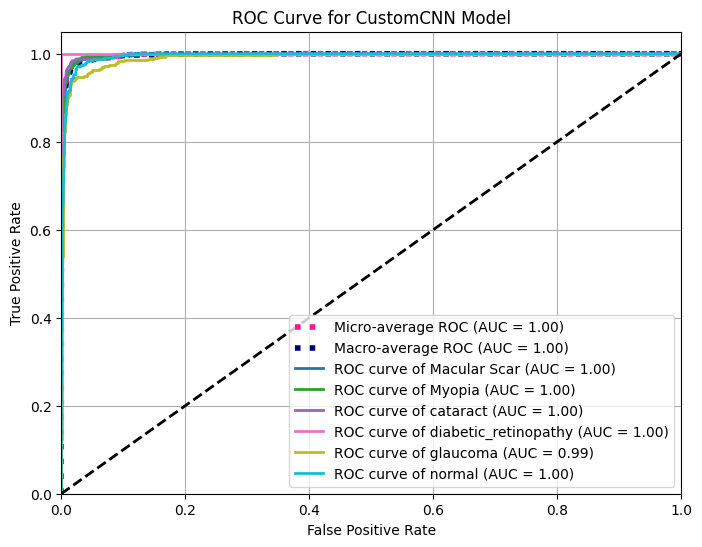

ROC AUC Scores: {0: 0.9978208, 1: 0.9979472, 2: 0.9974924000000001, 3: 0.9999999999999999, 4: 0.9924232, 5: 0.9951563999999999, 'micro': 0.9973562666666667, 'macro': 0.9969172666666666}


In [41]:
# Initialize and summarize CustomCNN
print("CustomCNN Model Summary:")
custom_model = CustomCNN().to(DEVICE)
summary(custom_model, input_size=(3, 224, 224))

# Train CustomCNN
print("\nTraining CustomCNN Model...")
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(custom_model.parameters(), lr=LEARNING_RATE)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
custom_model, custom_train_losses, custom_val_losses, custom_train_accs, custom_val_accs = train_custom_model(
    custom_model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, DEVICE, model_name="custom_cnn"
)

# Plot training curves
plot_training_curves(custom_train_losses, custom_val_losses, custom_train_accs, custom_val_accs, model_name="CustomCNN")

# Load best model and evaluate
custom_model.load_state_dict(torch.load("custom_cnn.pth"))
class_names = train_dataset.classes
custom_acc, custom_precision, custom_recall, custom_f1, custom_loss, custom_inf_time, custom_preds, custom_labels, custom_probs = evaluate_model(
    custom_model, test_loader, criterion, DEVICE, "CustomCNN Model", class_names=class_names
)

# Calculate model size
custom_size = calculate_model_size(custom_model, "custom_cnn", compress=True)
print(f"CustomCNN (Teacher) Model Size: {custom_size:.2f} MB")

# Plot confusion matrix
plot_confusion_matrix(custom_labels, custom_preds, class_names, model_name="CustomCNN Model")

# Plot ROC curve
roc_auc = plot_roc_curve(custom_labels, custom_probs, class_names, model_name="CustomCNN Model")
print(f"ROC AUC Scores: {roc_auc}")

# knowledge distillation

**In this project we use custom CNN model as a Teacher model. Now we create student model.**

In [86]:
class StudentCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(StudentCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 48, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(48)
        self.conv4 = nn.Conv2d(48, 64, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 14 * 14, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, num_classes)
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = self.pool(torch.relu(self.bn3(self.conv3(x))))
        x = self.pool(torch.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

StudentCNN Model Summary:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 224, 224]             448
       BatchNorm2d-2         [-1, 16, 224, 224]              32
         MaxPool2d-3         [-1, 16, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]           4,640
       BatchNorm2d-5         [-1, 32, 112, 112]              64
         MaxPool2d-6           [-1, 32, 56, 56]               0
            Conv2d-7           [-1, 48, 56, 56]          13,872
       BatchNorm2d-8           [-1, 48, 56, 56]              96
         MaxPool2d-9           [-1, 48, 28, 28]               0
           Conv2d-10           [-1, 64, 28, 28]          27,712
      BatchNorm2d-11           [-1, 64, 28, 28]             128
        MaxPool2d-12           [-1, 64, 14, 14]               0
           Linear-13                   [-1, 64]         802,880
          Dro

/tmp/ipykernel_31/4027814490.py:134: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  custom_model.load_state_dict(torch.load("custom_cnn.pth"))


Epoch 1/50, Train Loss: 2.9464, Train Acc: 56.14%, Val Loss: 0.6591, Val Acc: 69.93%
Best student model saved!
Epoch 2/50, Train Loss: 1.8702, Train Acc: 69.32%, Val Loss: 0.5192, Val Acc: 77.67%
Best student model saved!
Epoch 3/50, Train Loss: 1.5928, Train Acc: 73.90%, Val Loss: 0.6069, Val Acc: 75.73%
Epoch 4/50, Train Loss: 1.3884, Train Acc: 77.70%, Val Loss: 0.5025, Val Acc: 77.47%
Best student model saved!
Epoch 5/50, Train Loss: 1.2009, Train Acc: 80.42%, Val Loss: 0.4508, Val Acc: 82.67%
Best student model saved!
Epoch 6/50, Train Loss: 1.0458, Train Acc: 83.14%, Val Loss: 0.3807, Val Acc: 84.87%
Best student model saved!
Epoch 7/50, Train Loss: 0.9822, Train Acc: 84.34%, Val Loss: 0.3587, Val Acc: 85.87%
Best student model saved!
Epoch 8/50, Train Loss: 0.8515, Train Acc: 86.01%, Val Loss: 0.3586, Val Acc: 87.27%
Best student model saved!
Epoch 9/50, Train Loss: 0.7794, Train Acc: 87.44%, Val Loss: 0.3306, Val Acc: 87.13%
Best student model saved!
Epoch 10/50, Train Loss: 0.

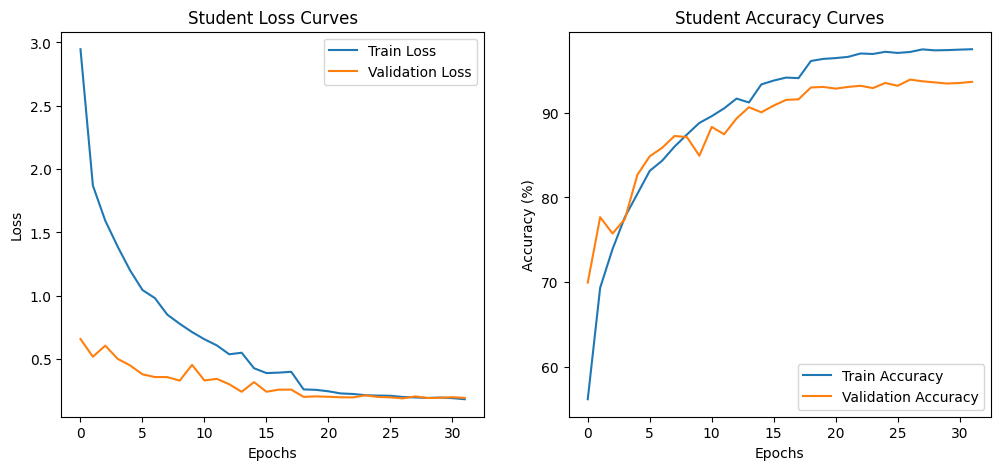

/tmp/ipykernel_31/4027814490.py:143: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  student_model.load_state_dict(torch.load("student_model.pth"))


Student Model Size: 3.02 MB


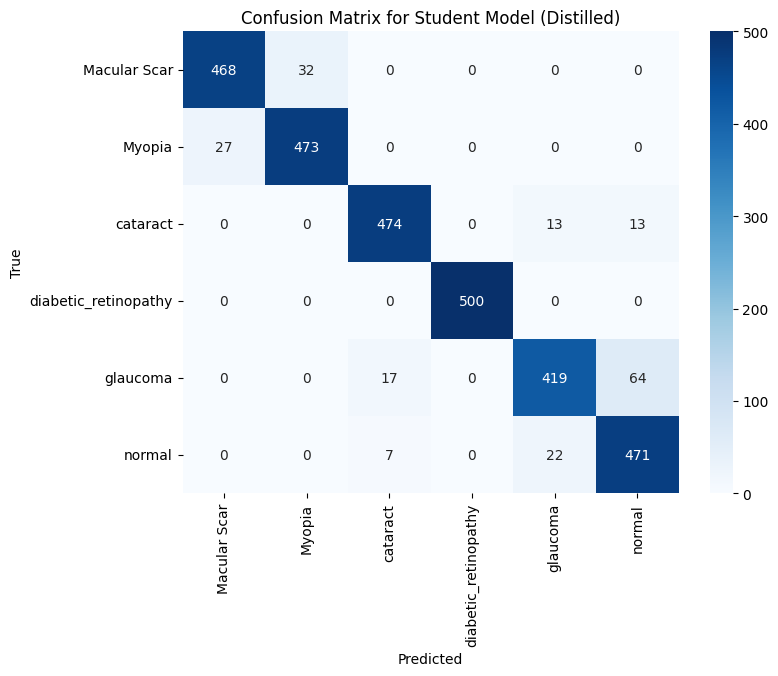

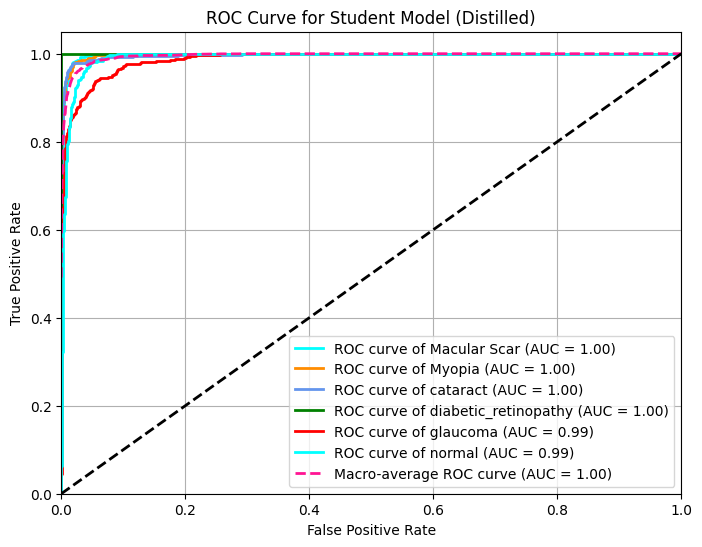

In [87]:
# Initialize and summarize StudentCNN
print("StudentCNN Model Summary:")
student_model = StudentCNN().to(DEVICE)
summary(student_model, input_size=(3, 224, 224))

# Knowledge Distillation Training Function
def train_knowledge_distillation(custom_model, student_model, train_loader, val_loader, epochs, temperature, alpha_kd, device):
    custom_model.eval()
    student_model.train()
    criterion_ce = nn.CrossEntropyLoss()
    criterion_kl = nn.KLDivLoss(reduction='batchmean')
    optimizer = optim.Adam(student_model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
    
    best_val_loss = float("inf")
    epochs_no_improve = 0
    train_losses, val_losses = [], []
    train_accuracies, val_accuracies = [], []
    
    for epoch in range(epochs):
        student_model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            with torch.no_grad():
                custom_outputs = custom_model(images)
            student_outputs = student_model(images)
            loss_ce = criterion_ce(student_outputs, labels)
            soft_custom = F.softmax(custom_outputs / temperature, dim=1)
            soft_student = F.log_softmax(student_outputs / temperature, dim=1)
            loss_kl = criterion_kl(soft_student, soft_custom) * (temperature ** 2)
            loss = alpha_kd * loss_kl + (1 - alpha_kd) * loss_ce
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            _, predicted = torch.max(student_outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
        
        avg_train_loss = total_loss / len(train_loader)
        train_accuracy = 100 * correct / total
        train_losses.append(avg_train_loss)
        train_accuracies.append(train_accuracy)
        
        student_model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = student_model(images)
                loss = criterion_ce(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)
        
        avg_val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * val_correct / val_total
        val_losses.append(avg_val_loss)
        val_accuracies.append(val_accuracy)
        
        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {avg_train_loss:.4f}, Train Acc: {train_accuracy:.2f}%, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_accuracy:.2f}%")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            epochs_no_improve = 0
            torch.save(student_model.state_dict(), "student_model.pth")
            print("Best student model saved!")
        else:
            epochs_no_improve += 1
        
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch+1}")
            break
        
        scheduler.step(avg_val_loss)
    
    return student_model, train_losses, val_losses, train_accuracies, val_accuracies

# Function to plot ROC curve
def plot_roc_curve(true_labels, pred_probs, class_names, model_name="Model", show_plot=True):
    n_classes = len(class_names)
    # Convert true labels to one-hot encoding
    true_labels_bin = np.zeros((len(true_labels), n_classes))
    for i, label in enumerate(true_labels):
        true_labels_bin[i, label] = 1
    
    # Compute ROC curve and ROC area for each class
    fpr = dict()
    tpr = dict()
    roc_auc = dict()
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(true_labels_bin[:, i], pred_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # Compute macro-average ROC curve
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])
    
    # Plot ROC curves
    plt.figure(figsize=(8, 6))
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'ROC curve of {class_names[i]} (AUC = {roc_auc[i]:.2f})')
    
    plt.plot(fpr["macro"], tpr["macro"], color='deeppink', linestyle='--', lw=2,
             label=f'Macro-average ROC curve (AUC = {roc_auc["macro"]:.2f})')
    
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.savefig(f'roc_curve_{model_name.lower().replace(" ", "_")}.png')
    if show_plot:
        plt.show()
    else:
        plt.close()

# Train and Evaluate Student Model
print("\nTraining Student Model with Knowledge Distillation...")
student_model = StudentCNN().to(DEVICE)
custom_model.load_state_dict(torch.load("custom_cnn.pth"))
student_model, student_train_losses, student_val_losses, student_train_accs, student_val_accs = train_knowledge_distillation(
    custom_model, student_model, train_loader, val_loader, NUM_EPOCHS, DISTILLATION_TEMPERATURE, ALPHA_KD, DEVICE
)

# Plot Training Curves
plot_training_curves(student_train_losses, student_val_losses, student_train_accs, student_val_accs, model_name="Student")

# Evaluate Student Model
student_model.load_state_dict(torch.load("student_model.pth"))
class_names = train_dataset.classes  # Get class names for confusion matrix and ROC curve

# Modified evaluation to collect probabilities for ROC curve
student_model.eval()
all_preds, all_labels, all_probs = [], [], []
total_loss, correct, total = 0, 0, 0
criterion = nn.CrossEntropyLoss()
start_time = torch.cuda.Event(enable_timing=True)
end_time = torch.cuda.Event(enable_timing=True)
total_inf_time = 0

with torch.no_grad():
    start_time.record()
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = student_model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(F.softmax(outputs, dim=1).cpu().numpy())
    end_time.record()
    torch.cuda.synchronize()
    total_inf_time = start_time.elapsed_time(end_time) / 1000  # Convert to seconds

avg_loss = total_loss / len(test_loader)
student_acc = 100 * correct / total
student_inf_time = total_inf_time / len(test_loader.dataset)
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)
all_preds = np.array(all_preds)

# Assume evaluate_model returns these metrics (adjust if needed)
precision, recall, f1, cm = 0, 0, 0, None  # Placeholder; replace with actual evaluate_model logic if needed
eval_results = (student_acc, precision, recall, f1, cm, student_inf_time, all_preds, all_labels)

# Unpack results
student_acc, precision, recall, f1, cm, student_inf_time, student_preds, student_labels = eval_results[:8]
student_size = calculate_model_size(student_model, "student_model", compress=True)
print(f"Student Model Size: {student_size:.2f} MB")

# Plot Confusion Matrix
plot_confusion_matrix(student_labels, student_preds, class_names, model_name="Student Model (Distilled)")

# Plot ROC Curve
plot_roc_curve(student_labels, all_probs, class_names, model_name="Student Model (Distilled)", show_plot=True)

In [89]:
# Evaluate Student Model
student_model = StudentCNN().to(DEVICE)
student_model.load_state_dict(torch.load("student_model.pth"))
student_acc, student_precision, student_recall, student_f1, student_loss, student_inf_time, student_preds, student_labels, student_probs = evaluate_model(
    student_model, test_loader, criterion, DEVICE, "Student (Distilled)", class_names=class_names
)
student_size = calculate_model_size(student_model, "student_model", compress=True)
print(f"Student (Distilled) Model Size: {student_size:.2f} MB")

/tmp/ipykernel_31/289237484.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  student_model.load_state_dict(torch.load("student_model.pth"))



Evaluation Metrics for Student (Distilled):
Accuracy: 93.50%
Precision: 93.60%
Recall: 93.50%
F1 Score: 93.49%
Average Inference Time per Batch: 1.20 ms
Student (Distilled) Model Size: 3.02 MB


# Pruning

In [104]:
import torch.nn.utils.prune as prune

In [118]:
# Pruning Functions
def apply_unstructured_pruning(model, pruning_amount=0.2):
    layers_to_prune = [
        (model.conv1, 'weight'),
        (model.conv2, 'weight'),
        (model.conv3, 'weight'),
        (model.conv4, 'weight'),
        (model.conv5, 'weight'),
        (model.fc1, 'weight'),
        (model.fc2, 'weight'),
        (model.fc3, 'weight')
    ]
    for module, name in layers_to_prune:
        prune.l1_unstructured(module, name=name, amount=pruning_amount)
        if hasattr(module, 'bias') and module.bias is not None:
            prune.l1_unstructured(module, name='bias', amount=pruning_amount)
    return model

def permanently_remove_pruning(model):
    layers_to_prune = [
        (model.conv1, 'weight'),
        (model.conv2, 'weight'),
        (model.conv3, 'weight'),
        (model.conv4, 'weight'),
        (model.conv5, 'weight'),
        (model.fc1, 'weight'),
        (model.fc2, 'weight'),
        (model.fc3, 'weight'),
        (model.conv1, 'bias'),
        (model.conv2, 'bias'),
        (model.conv3, 'bias'),
        (model.conv4, 'bias'),
        (model.conv5, 'bias'),
        (model.fc1, 'bias'),
        (model.fc2, 'bias'),
        (model.fc3, 'bias')
    ]
    for module, name in layers_to_prune:
        if hasattr(module, f"{name}_mask"):
            prune.remove(module, name)
    return model

def calculate_sparsity(model):
    total_params = 0
    zero_params = 0
    for param in model.parameters():
        total_params += param.numel()
        zero_params += (param == 0).sum().item()
    return 100 * zero_params / total_params if total_params > 0 else 0

In [120]:
# Fine-Tuning Function
def fine_tune_model(model, train_loader, val_loader, criterion, epochs, lr, device):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)
    for epoch in range(epochs):
        model.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                val_loss += criterion(outputs, labels).item()
        val_loss /= len(val_loader)
        scheduler.step(val_loss)
        print(f"Fine-tuning Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}")
    return model

In [121]:
# Pruning Custom CNN (Teacher) Model
sparsity_levels = [0.2, 0.5, 0.7]
results = {
    "sparsity": [],
    "size_mb": [],
    "accuracy": [],
    "inference_time_ms": []
}

print("\nPruning Custom CNN (Teacher) Model...")
for pruning_amount in sparsity_levels:
    print(f"\nPruning at {pruning_amount*100}% Sparsity:")
    model_pruned = CustomCNN().to(DEVICE)
    model_pruned.load_state_dict(torch.load("custom_cnn.pth"))
    model_pruned = apply_unstructured_pruning(model_pruned, pruning_amount=pruning_amount)
    
    # Evaluate before fine-tuning
    acc_no_ft, _, _, _, _, inf_time_no_ft, _, _, _ = evaluate_model(
        model_pruned, test_loader, criterion, DEVICE, f"Pruned Custom CNN (Sparsity {pruning_amount*100}%, No Fine-Tune)", class_names=class_names
    )
    
    # Permanently remove pruning
    model_pruned = permanently_remove_pruning(model_pruned)
    
    # Calculate sparsity and size
    sparsity = calculate_sparsity(model_pruned)
    size_mb = calculate_model_size(model_pruned, f"pruned_custom_{int(pruning_amount*100)}", compress=True)
    
    # Fine-tune
    model_pruned = fine_tune_model(model_pruned, train_loader, val_loader, criterion, NUM_FINE_TUNE_EPOCHS, FINE_TUNE_LR, DEVICE)
    
    # Evaluate after fine-tuning
    acc_ft, _, _, _, _, inf_time_ft, _, _, _ = evaluate_model(
        model_pruned, test_loader, criterion, DEVICE, f"Pruned Custom CNN (Sparsity {pruning_amount*100}%, Fine-Tuned)", class_names=class_names
    )
    
    results["sparsity"].append(sparsity)
    results["size_mb"].append(size_mb)
    results["accuracy"].append(acc_ft)
    results["inference_time_ms"].append(inf_time_ft)
    
    print(f"Sparsity Achieved: {sparsity:.2f}%")
    print(f"Pruned Model Size: {size_mb:.2f} MB")


Pruning Custom CNN (Teacher) Model...

Pruning at 20.0% Sparsity:


/tmp/ipykernel_31/2641200035.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pruned.load_state_dict(torch.load("custom_cnn.pth"))



Evaluation Metrics for Pruned Custom CNN (Sparsity 20.0%, No Fine-Tune):
Accuracy: 95.00%
Precision: 95.05%
Recall: 95.00%
F1 Score: 94.99%
Average Inference Time per Batch: 2.04 ms
Fine-tuning Epoch 1/5, Val Loss: 0.1657
Fine-tuning Epoch 2/5, Val Loss: 0.1566
Fine-tuning Epoch 3/5, Val Loss: 0.1782
Fine-tuning Epoch 4/5, Val Loss: 0.1576
Fine-tuning Epoch 5/5, Val Loss: 0.1672

Evaluation Metrics for Pruned Custom CNN (Sparsity 20.0%, Fine-Tuned):
Accuracy: 95.43%
Precision: 95.46%
Recall: 95.43%
F1 Score: 95.43%
Average Inference Time per Batch: 1.46 ms
Sparsity Achieved: 19.99%
Pruned Model Size: 6.33 MB

Pruning at 50.0% Sparsity:


/tmp/ipykernel_31/2641200035.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pruned.load_state_dict(torch.load("custom_cnn.pth"))



Evaluation Metrics for Pruned Custom CNN (Sparsity 50.0%, No Fine-Tune):
Accuracy: 23.90%
Precision: 66.64%
Recall: 23.90%
F1 Score: 16.60%
Average Inference Time per Batch: 1.97 ms
Fine-tuning Epoch 1/5, Val Loss: 0.1605
Fine-tuning Epoch 2/5, Val Loss: 0.1572
Fine-tuning Epoch 3/5, Val Loss: 0.1756
Fine-tuning Epoch 4/5, Val Loss: 0.1616
Fine-tuning Epoch 5/5, Val Loss: 0.1768

Evaluation Metrics for Pruned Custom CNN (Sparsity 50.0%, Fine-Tuned):
Accuracy: 94.90%
Precision: 94.93%
Recall: 94.90%
F1 Score: 94.90%
Average Inference Time per Batch: 1.46 ms
Sparsity Achieved: 49.97%
Pruned Model Size: 4.33 MB

Pruning at 70.0% Sparsity:


/tmp/ipykernel_31/2641200035.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_pruned.load_state_dict(torch.load("custom_cnn.pth"))
/usr/local/lib/python3.11/dist-p


Evaluation Metrics for Pruned Custom CNN (Sparsity 70.0%, No Fine-Tune):
Accuracy: 17.33%
Precision: 18.67%
Recall: 17.33%
F1 Score: 6.07%
Average Inference Time per Batch: 2.01 ms
Fine-tuning Epoch 1/5, Val Loss: 0.1701
Fine-tuning Epoch 2/5, Val Loss: 0.1684
Fine-tuning Epoch 3/5, Val Loss: 0.1583
Fine-tuning Epoch 4/5, Val Loss: 0.1676
Fine-tuning Epoch 5/5, Val Loss: 0.1632

Evaluation Metrics for Pruned Custom CNN (Sparsity 70.0%, Fine-Tuned):
Accuracy: 95.07%
Precision: 95.09%
Recall: 95.07%
F1 Score: 95.06%
Average Inference Time per Batch: 1.42 ms
Sparsity Achieved: 69.96%
Pruned Model Size: 2.84 MB


In [122]:
# Evaluate Custom CNN (Teacher) Model
teacher_model = CustomCNN().to(DEVICE)
teacher_model.load_state_dict(torch.load("custom_cnn.pth"))
teacher_acc, teacher_precision, teacher_recall, teacher_f1, teacher_loss, teacher_inf_time, teacher_preds, teacher_labels, teacher_probs = evaluate_model(
    teacher_model, test_loader, criterion, DEVICE, "CustomCNN (Teacher)", class_names=class_names
)
teacher_size = calculate_model_size(teacher_model, "custom_cnn", compress=True)
print(f"CustomCNN (Teacher) Model Size: {teacher_size:.2f} MB")

# Evaluate Student Model
student_model = StudentCNN().to(DEVICE)
student_model.load_state_dict(torch.load("student_model.pth"))
student_acc, student_precision, student_recall, student_f1, student_loss, student_inf_time, student_preds, student_labels, student_probs = evaluate_model(
    student_model, test_loader, criterion, DEVICE, "Student (Distilled)", class_names=class_names
)
student_size = calculate_model_size(student_model, "student_model", compress=True)
print(f"Student (Distilled) Model Size: {student_size:.2f} MB")

/tmp/ipykernel_31/3449355872.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  teacher_model.load_state_dict(torch.load("custom_cnn.pth"))



Evaluation Metrics for CustomCNN (Teacher):
Accuracy: 95.07%
Precision: 95.10%
Recall: 95.07%
F1 Score: 95.06%
Average Inference Time per Batch: 1.42 ms
CustomCNN (Teacher) Model Size: 7.42 MB


/tmp/ipykernel_31/3449355872.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  student_model.load_state_dict(torch.load("student_model.pth"))



Evaluation Metrics for Student (Distilled):
Accuracy: 93.50%
Precision: 93.60%
Recall: 93.50%
F1 Score: 93.49%
Average Inference Time per Batch: 1.20 ms
Student (Distilled) Model Size: 3.02 MB


/tmp/ipykernel_31/2432213053.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn')


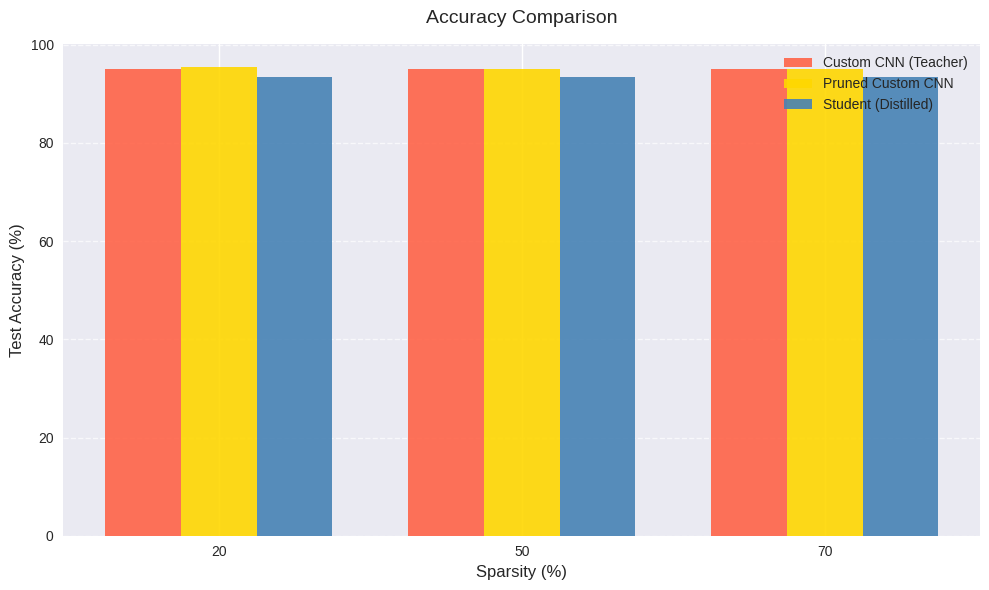

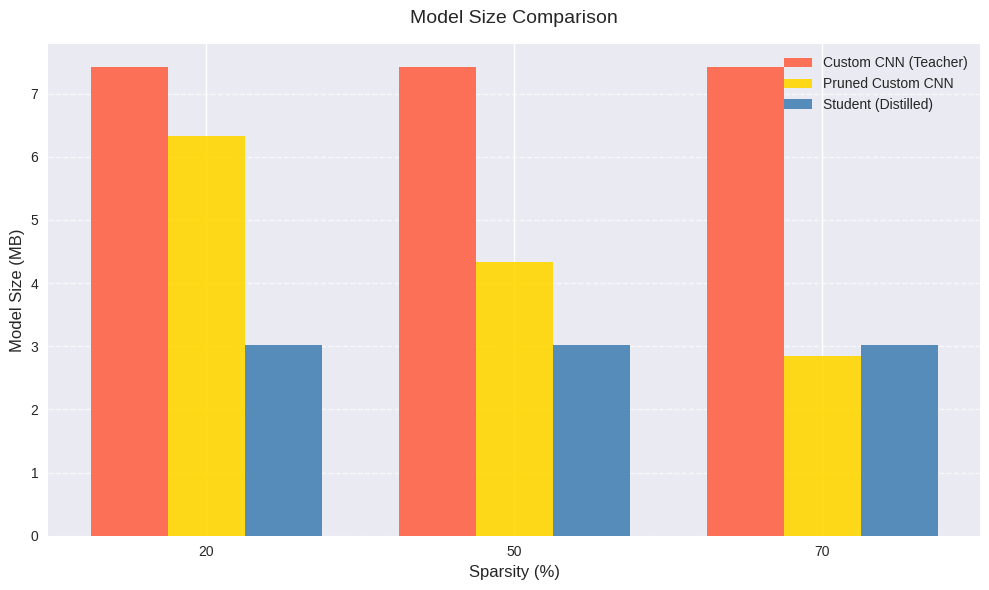

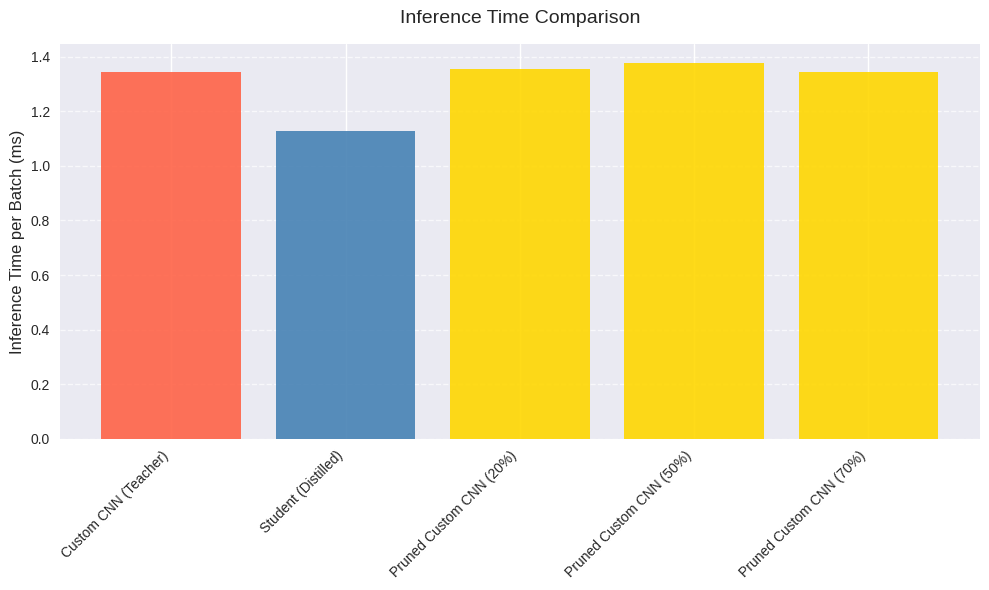

In [102]:
# Set global plot style
plt.style.use('seaborn')
colors = {'teacher': '#FF6347', 'pruned': '#FFD700', 'student': '#4682B4'}
labels = ['Custom CNN (Teacher)', 'Pruned Custom CNN', 'Student (Distilled)']

# Accuracy Comparison
plt.figure(figsize=(10, 6))
x = np.arange(len(results["sparsity"]))
width = 0.25
plt.bar(x - width, [teacher_acc] * len(x), width, label=labels[0], color=colors['teacher'], alpha=0.9)
plt.bar(x, results["accuracy"], width, label=labels[1], color=colors['pruned'], alpha=0.9)
plt.bar(x + width, [student_acc] * len(x), width, label=labels[2], color=colors['student'], alpha=0.9)
plt.xlabel("Sparsity (%)", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.title("Accuracy Comparison", fontsize=14, pad=15)
plt.xticks(x, [f"{s:.0f}" for s in results["sparsity"]], fontsize=10)
plt.legend(fontsize=10, loc='best')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Model Size Comparison
plt.figure(figsize=(10, 6))
plt.bar(x - width, [teacher_size] * len(x), width, label=labels[0], color=colors['teacher'], alpha=0.9)
plt.bar(x, results["size_mb"], width, label=labels[1], color=colors['pruned'], alpha=0.9)
plt.bar(x + width, [student_size] * len(x), width, label=labels[2], color=colors['student'], alpha=0.9)
plt.xlabel("Sparsity (%)", fontsize=12)
plt.ylabel("Model Size (MB)", fontsize=12)
plt.title("Model Size Comparison", fontsize=14, pad=15)
plt.xticks(x, [f"{s:.0f}" for s in results["sparsity"]], fontsize=10)
plt.legend(fontsize=10, loc='best')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Inference Time Comparison
plt.figure(figsize=(10, 6))
models = [labels[0], labels[2], f"{labels[1]} (20%)", f"{labels[1]} (50%)", f"{labels[1]} (70%)"]
times = [teacher_inf_time, student_inf_time] + results["inference_time_ms"]
colors_inf = [colors['teacher'], colors['student']] + [colors['pruned']] * 3
plt.bar(models, times, color=colors_inf, alpha=0.9)
plt.ylabel("Inference Time per Batch (ms)", fontsize=12)
plt.title("Inference Time Comparison", fontsize=14, pad=15)
plt.xticks(rotation=45, fontsize=10, ha='right')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# XAI

**Grad CAM**

In [37]:
import torch
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [39]:
# GradCAM Class
class GradCAM_Article:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer._backward_hooks.clear()
        self.target_layer._forward_hooks.clear()
        self.target_layer.register_forward_hook(self.save_activations)
        self.target_layer.register_full_backward_hook(self.save_gradients)

    def save_activations(self, module, input, output):
        self.activations = output

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_image, target_class=None):
        self.model.eval()
        input_image = input_image.requires_grad_(True)
        output = self.model(input_image)
        if target_class is None:
            target_class = torch.argmax(output, dim=1).item()
        
        self.model.zero_grad()
        output[0, target_class].backward()
        
        gradients = self.gradients
        activations = self.activations
        if gradients is None or activations is None:
            raise ValueError("Gradients or activations not captured. Check hook registration.")
        
        weights = torch.mean(gradients, dim=[2, 3], keepdim=True)
        grad_cam = F.relu(torch.sum(weights * activations, dim=1))
        
        grad_cam = grad_cam - grad_cam.min()
        grad_cam = grad_cam / (grad_cam.max() + 1e-8)
        
        grad_cam = F.interpolate(grad_cam.unsqueeze(0), size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
        grad_cam = grad_cam.squeeze().detach().cpu().numpy()
        return grad_cam

In [40]:
# Overlay Grad-CAM on Image
def overlay_gradcam_on_image(original_image, gradcam, alpha=0.4):
    original_image = original_image.permute(1, 2, 0).detach().cpu().numpy()
    original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())
    heatmap = cv2.resize(gradcam, (original_image.shape[1], original_image.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = heatmap / 255.0
    superimposed_img = heatmap * alpha + original_image * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)
    return superimposed_img


Generating Grad-CAM Visualizations for CustomCNN (Teacher) Model...


/tmp/ipykernel_31/4226029839.py:76: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  teacher_model.load_state_dict(torch.load("custom_cnn.pth"))
/tmp/ipykernel_31/4226029839.py

Displaying Grad-CAM for class: Macular Scar (CustomCNN (Teacher))


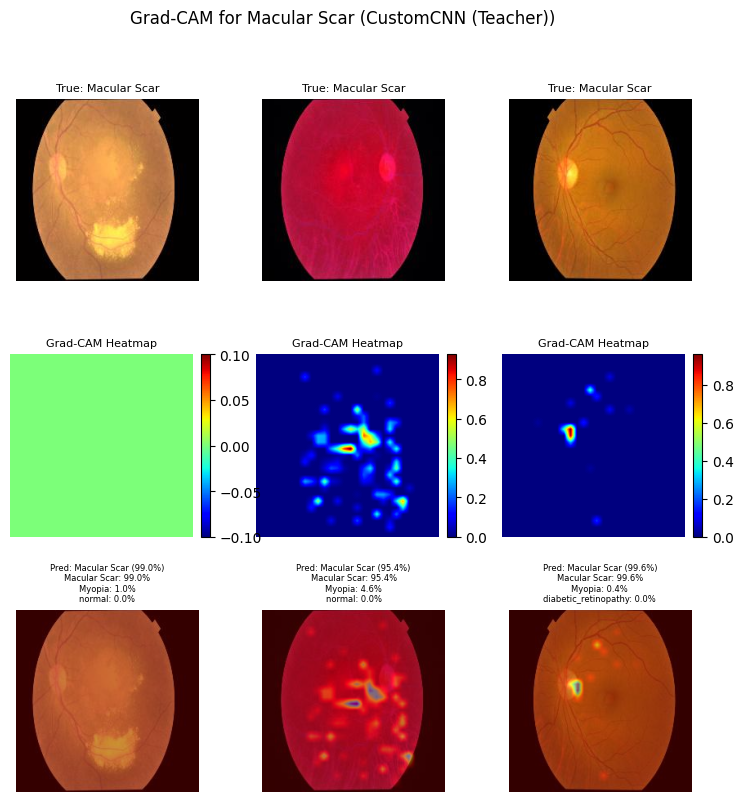

Displaying Grad-CAM for class: Myopia (CustomCNN (Teacher))


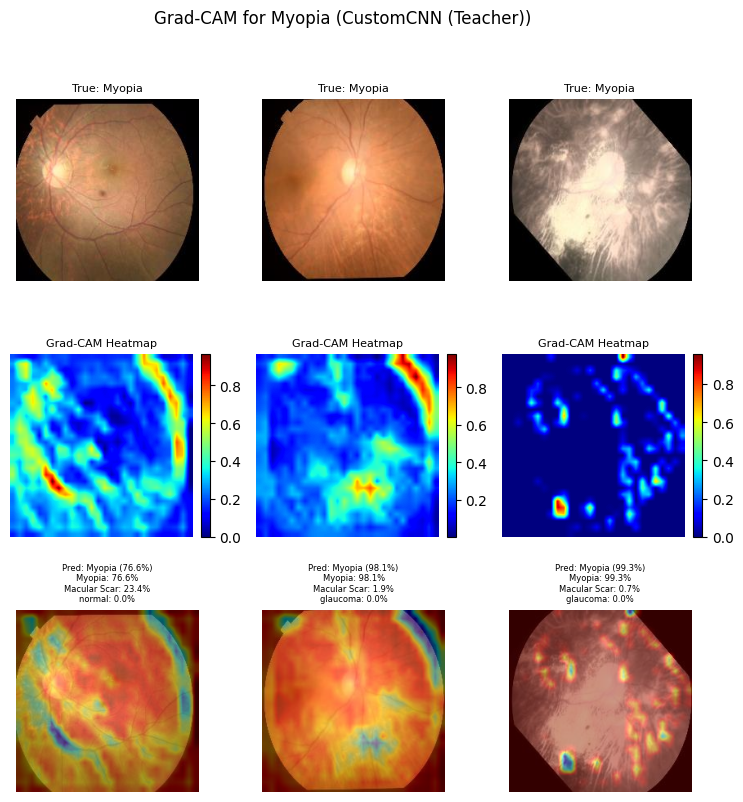

Displaying Grad-CAM for class: cataract (CustomCNN (Teacher))


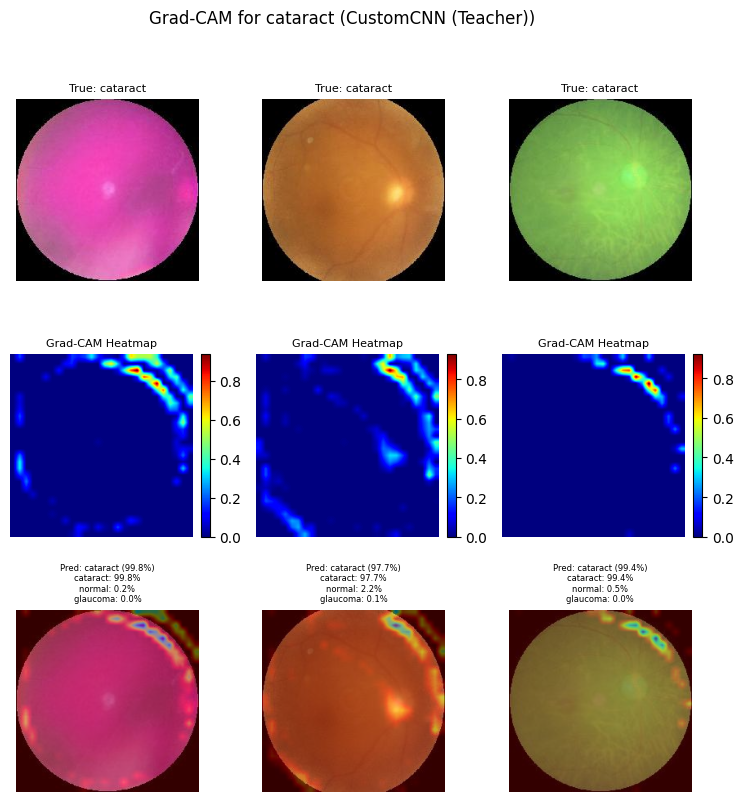

Displaying Grad-CAM for class: diabetic_retinopathy (CustomCNN (Teacher))


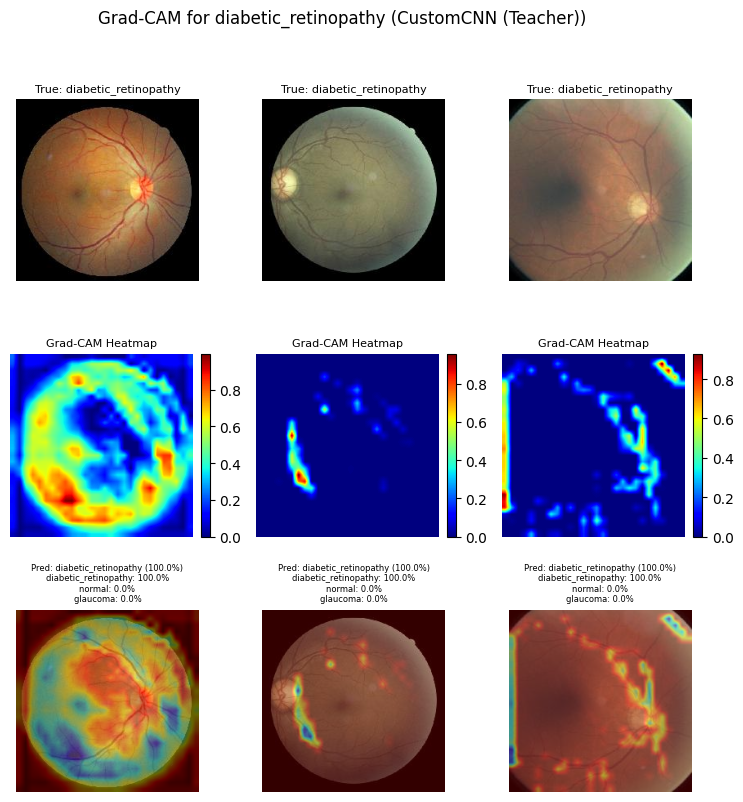

Displaying Grad-CAM for class: glaucoma (CustomCNN (Teacher))


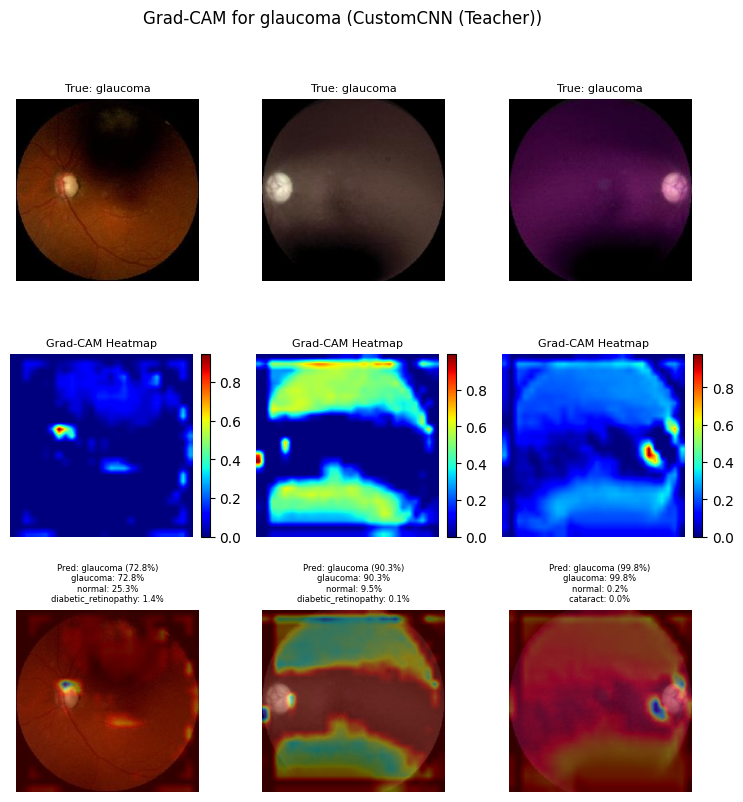

Displaying Grad-CAM for class: normal (CustomCNN (Teacher))


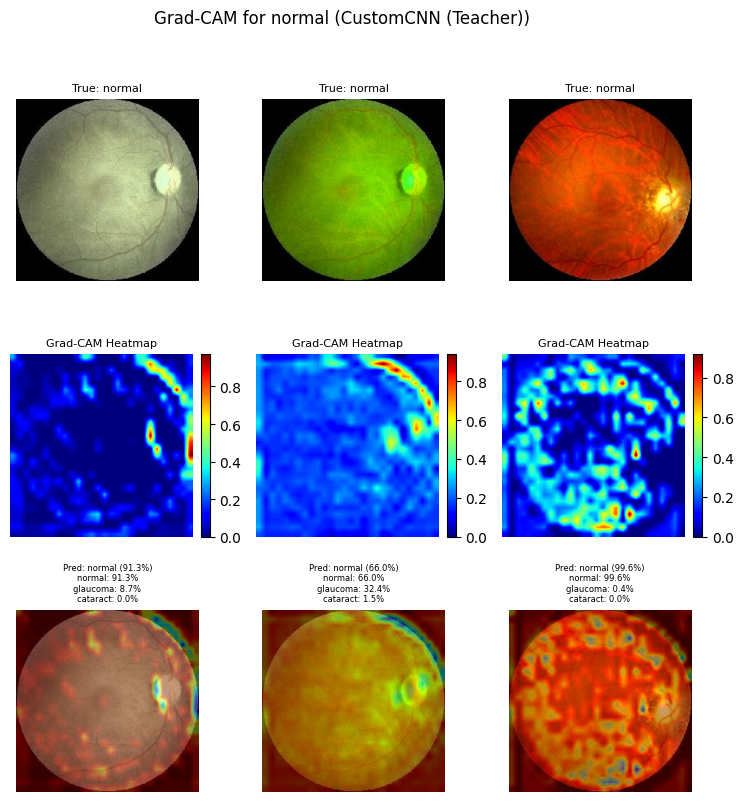

In [42]:
# Visualize Grad-CAM for CustomCNN
def visualize_gradcam_custom_cnn(model, test_loader, num_images_per_class=3, alpha=0.4, model_name="CustomCNN (Teacher)"):
    model.eval()
    target_layer = model.conv4  
    gradcam = GradCAM_Article(model, target_layer)
    class_names = test_dataset.classes
    
    class_examples = {i: [] for i in range(NUM_CLASSES)}
    print(f"Collecting {num_images_per_class} correctly classified images per class for Grad-CAM visualization...")
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with torch.no_grad():
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            pred_probs, pred_labels = torch.max(probs, dim=1)
            top3_probs, top3_labels = torch.topk(probs, k=3, dim=1)
        for i in range(images.size(0)):
            true_label = labels[i].item()
            pred_label = pred_labels[i].item()
            if pred_label == true_label and len(class_examples[true_label]) < num_images_per_class:
                class_examples[true_label].append((images[i], pred_labels[i], pred_probs[i], true_label, top3_probs[i], top3_labels[i]))
            if all(len(examples) >= num_images_per_class for examples in class_examples.values()):
                break
        if all(len(examples) >= num_images_per_class for examples in class_examples.values()):
            break
    
    for class_idx in range(NUM_CLASSES):
        examples = class_examples[class_idx]
        if len(examples) == 0:
            print(f"No correctly classified examples found for class: {class_names[class_idx]}")
            continue
        fig, axes = plt.subplots(3, num_images_per_class, figsize=(num_images_per_class * 3, 9), gridspec_kw={'wspace': 0.2, 'hspace': 0.4})
        if num_images_per_class == 1:
            axes = np.array([[axes[0]], [axes[1]], [axes[2]]])
        
        for img_idx in range(min(num_images_per_class, len(examples))):
            image, pred_label, pred_prob, true_label, top3_probs, top3_labels = examples[img_idx]
            image = image.unsqueeze(0)
            gradcam_map = gradcam.generate(image)
            
            top3_info = "\n".join([f"{class_names[top3_labels[j].item()]}: {top3_probs[j].item()*100:.1f}%"
                                   for j in range(3)])
            
            # Original image
            orig_img = image.squeeze().permute(1, 2, 0).detach().cpu().numpy()
            orig_img = (orig_img - orig_img.min()) / (orig_img.max() - orig_img.min())
            ax = axes[0, img_idx]
            ax.imshow(orig_img, aspect='equal')
            ax.set_title(f"True: {class_names[true_label]}", fontsize=8)
            ax.axis('off')
            
            # Grad-CAM heatmap with colorbar
            heatmap = cv2.resize(gradcam_map, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
            ax = axes[1, img_idx]
            im = ax.imshow(heatmap, cmap='jet', aspect='equal')
            ax.set_title("Grad-CAM Heatmap", fontsize=8)
            ax.axis('off')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            
            
            superimposed_img = overlay_gradcam_on_image(image.squeeze(), gradcam_map, alpha=alpha)
            ax = axes[2, img_idx]
            ax.imshow(superimposed_img, aspect='equal')
            ax.set_title(f"Pred: {class_names[pred_label.item()]} ({pred_prob.item()*100:.1f}%)\n{top3_info}", fontsize=6)
            ax.axis('off')
        
        plt.suptitle(f"Grad-CAM for {class_names[class_idx]} ({model_name})", fontsize=12)
        plt.tight_layout(rect=[0, 0, 1, 0.95])
        print(f"Displaying Grad-CAM for class: {class_names[class_idx]} ({model_name})")
        plt.show()
        plt.close(fig)

# Load and visualize Grad-CAM for CustomCNN
print("\nGenerating Grad-CAM Visualizations for CustomCNN (Teacher) Model...")
teacher_model = CustomCNN().to(DEVICE)
teacher_model.load_state_dict(torch.load("custom_cnn.pth"))
visualize_gradcam_custom_cnn(teacher_model, test_loader, num_images_per_class=3, model_name="CustomCNN (Teacher)")

**LIME**

In [32]:
from lime import lime_image
from skimage.segmentation import slic

In [33]:
# LIME Explanation Class
class LIMEExplainer:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.explainer = lime_image.LimeImageExplainer()

    def predict_fn(self, images):
        images = np.transpose(images, (0, 3, 1, 2))  
        images = torch.from_numpy(images).float() / 255.0
        images = images.contiguous().to(self.device)  #
        with torch.no_grad():
            outputs = self.model(images)
            probs = F.softmax(outputs, dim=1)
        return probs.cpu().numpy()

    def generate(self, image, target_class=None, num_samples=1000, num_segments=50):
        
        image_np = image.permute(1, 2, 0).cpu().numpy()
        image_np = (image_np - image_np.min()) / (image_np.max() - image_np.min())
        image_np = (image_np * 255).astype(np.uint8)

        
        explanation = self.explainer.explain_instance(
            image_np,
            self.predict_fn,
            top_labels=1,
            hide_color=0,
            num_samples=num_samples,
            segmentation_fn=lambda x: self._segment_image(x, num_segments)
        )

       
        if target_class is None:
            target_class = explanation.top_labels[0]

       
        mask = explanation.get_image_and_mask(
            target_class,
            positive_only=True,
            num_features=5,
            hide_rest=False
        )[1]

        
        mask = mask.astype(float)
        mask = (mask - mask.min()) / (mask.max() - mask.min() + 1e-8)

        return mask, image_np

    def _segment_image(self, image, num_segments):
        return slic(image, n_segments=num_segments, compactness=10, sigma=1)

In [35]:
# Overlay function for LIME explanation
def overlay_lime_on_image(original_image, lime_mask, alpha=0.4):
    original_image = original_image / 255.0  # Already in (H, W, C) format
    heatmap = cv2.resize(lime_mask, (original_image.shape[1], original_image.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = heatmap / 255.0
    superimposed_img = heatmap * alpha + original_image * (1 - alpha)
    superimposed_img = np.clip(superimposed_img, 0, 1)
    return superimposed_img


Generating LIME Visualizations for Teacher Model...


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: Macular Scar (CustomCNN (Teacher))


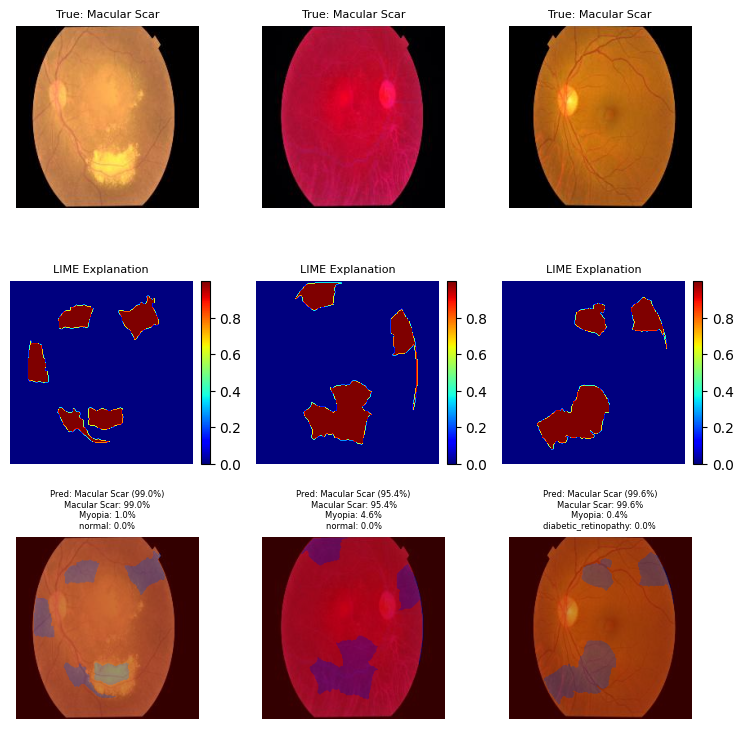

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: Myopia (CustomCNN (Teacher))


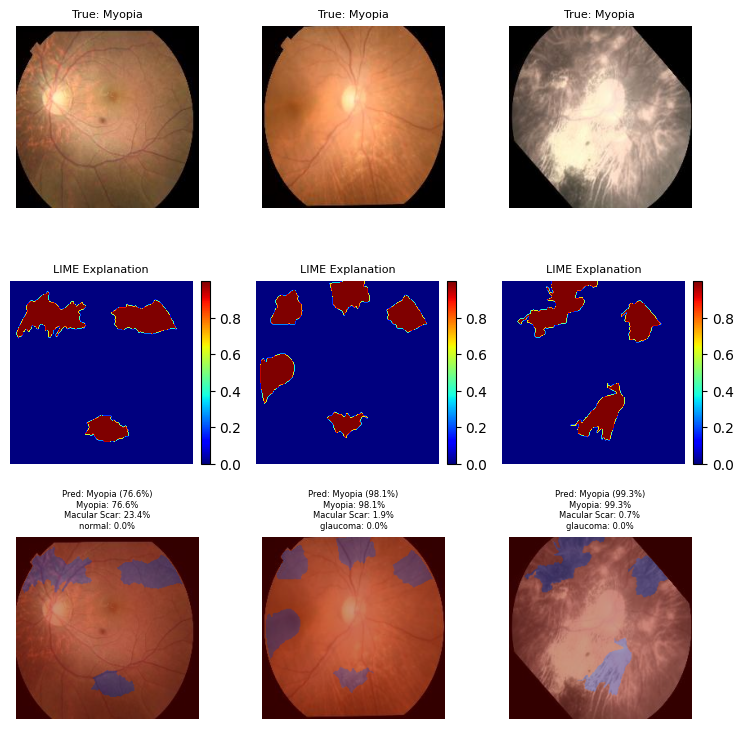

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: cataract (CustomCNN (Teacher))


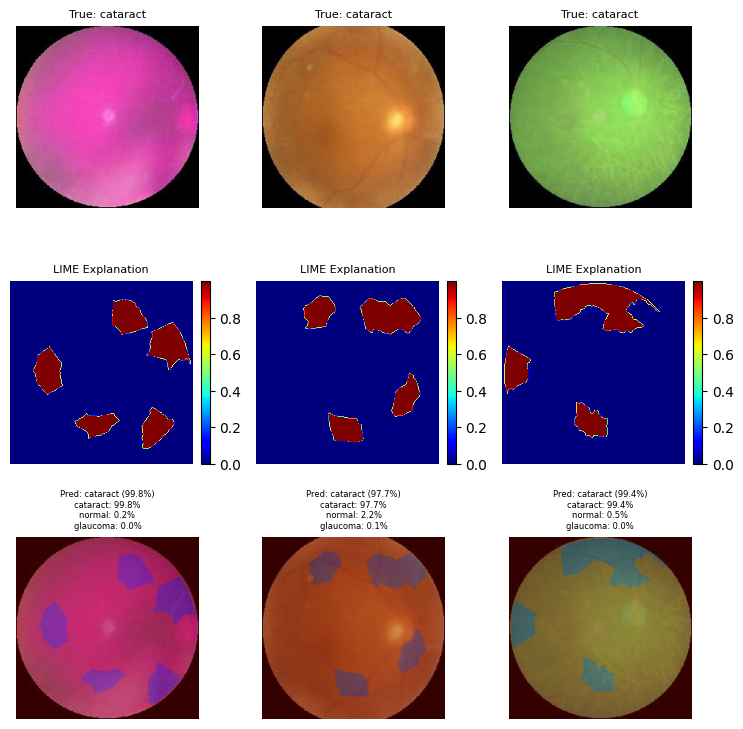

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: diabetic_retinopathy (CustomCNN (Teacher))


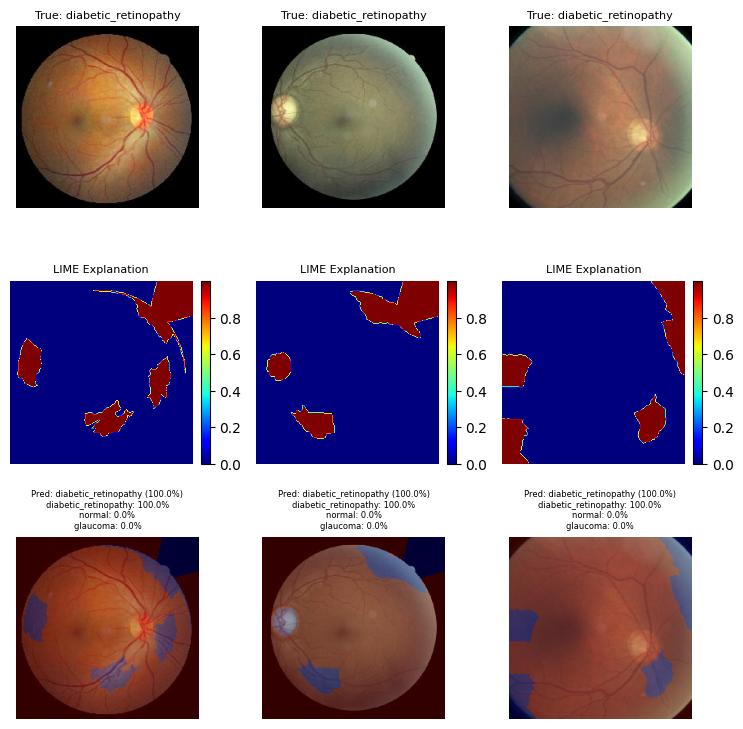

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: glaucoma (CustomCNN (Teacher))


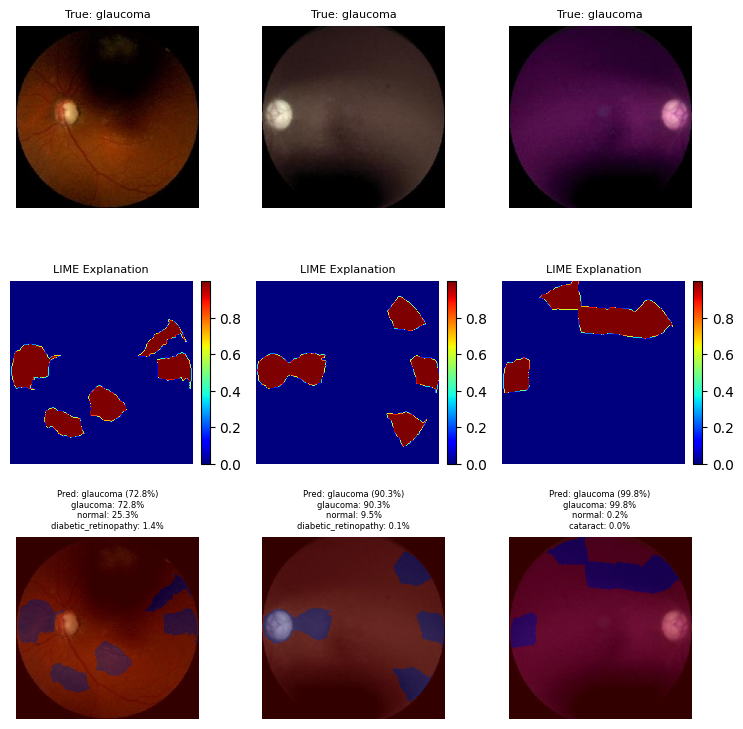

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_31/4043739847.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Displaying combined LIME explanation for class: normal (CustomCNN (Teacher))


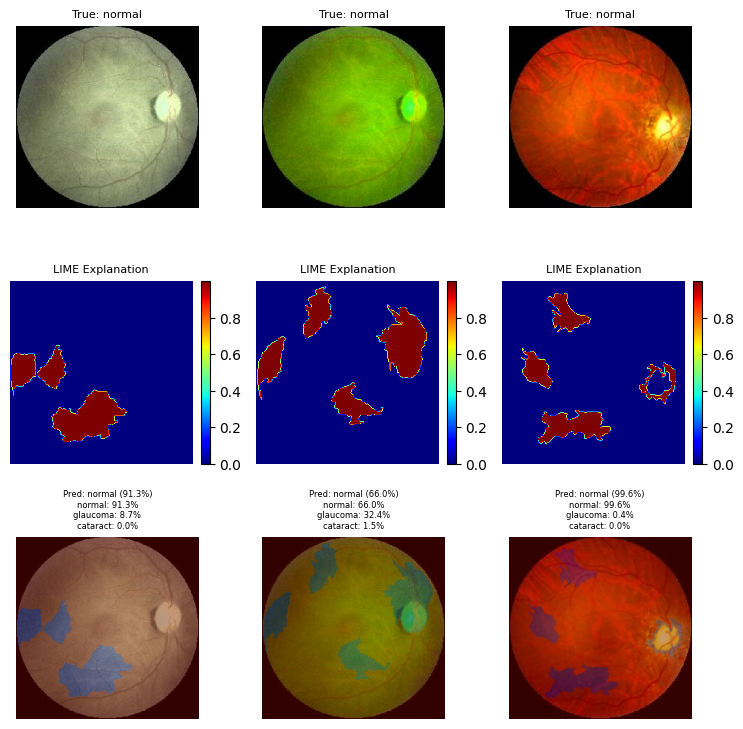

In [36]:
# Visualization function for LIME
def visualize_lime_teacher(model, test_loader, num_images_per_class=3, save_dir="gradcam_outputs_teacher", alpha=0.4, model_name="Teacher"):
    model.eval()
    lime_explainer = LIMEExplainer(model, DEVICE)
    class_names = test_dataset.classes
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)
    
    class_examples = {i: [] for i in range(NUM_CLASSES)}
    print(f"Collecting {num_images_per_class} correctly classified images per class for LIME visualization...")
    for images, labels in test_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        with torch.no_grad():
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            pred_probs, pred_labels = torch.max(probs, dim=1)
            top3_probs, top3_labels = torch.topk(probs, k=3, dim=1)
        for i in range(images.size(0)):
            true_label = labels[i].item()
            pred_label = pred_labels[i].item()
            if pred_label == true_label and len(class_examples[true_label]) < num_images_per_class:
                class_examples[true_label].append((images[i], pred_labels[i], pred_probs[i], true_label, top3_probs[i], top3_labels[i]))
            if all(len(examples) >= num_images_per_class for examples in class_examples.values()):
                break
        if all(len(examples) >= num_images_per_class for examples in class_examples.values()):
            break
    
    for class_idx in range(NUM_CLASSES):
        examples = class_examples[class_idx]
        if len(examples) == 0:
            print(f"No correctly classified examples found for class: {class_names[class_idx]}")
            continue
        fig, axes = plt.subplots(3, num_images_per_class, figsize=(num_images_per_class * 3, 9), gridspec_kw={'wspace': 0.2, 'hspace': 0.4})
        if num_images_per_class == 1:
            axes = np.array([[axes[0]], [axes[1]], [axes[2]]])
        
        for img_idx in range(min(num_images_per_class, len(examples))):
            image, pred_label, pred_prob, true_label, top3_probs, top3_labels = examples[img_idx]
            image = image.unsqueeze(0)
            lime_mask, image_np = lime_explainer.generate(image.squeeze())
            
            
            top3_info = "\n".join([f"{class_names[top3_labels[j].item()]}: {top3_probs[j].item()*100:.1f}%"
                                   for j in range(3)])
            
            
            ax = axes[0, img_idx]
            ax.imshow(image_np, aspect='equal')
            ax.set_title(f"True: {class_names[true_label]}", fontsize=8)
            ax.axis('off')
            
           
            heatmap = cv2.resize(lime_mask, (image_np.shape[1], image_np.shape[0]), interpolation=cv2.INTER_LINEAR)
            ax = axes[1, img_idx]
            im = ax.imshow(heatmap, cmap='jet', aspect='equal')
            ax.set_title("LIME Explanation", fontsize=8)
            ax.axis('off')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
            
            
            superimposed_img = overlay_lime_on_image(image_np, lime_mask, alpha=alpha)
            ax = axes[2, img_idx]
            ax.imshow(superimposed_img, aspect='equal')
            ax.set_title(f"Pred: {class_names[pred_label.item()]} ({pred_prob.item()*100:.1f}%)\n{top3_info}", fontsize=6)
            ax.axis('off')
        
        plt.tight_layout()
        print(f"Displaying combined LIME explanation for class: {class_names[class_idx]} ({model_name})")
        plt.show()
        plt.close(fig)

# Call the function for the teacher model
print("\nGenerating LIME Visualizations for Teacher Model...")
teacher_model.load_state_dict(torch.load("custom_cnn.pth", weights_only=True))
visualize_lime_teacher(teacher_model, test_loader, num_images_per_class=3, save_dir="gradcam_outputs_teacher", model_name="CustomCNN (Teacher)")